In [1]:
# 1.  install the package
!pip -q install gbert

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 432.0/432.0 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 77.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 26.5 MB/s eta 0:00:00


In [2]:
from gbert import GbertClassifier, load_demo_corpus_ja_us_de_1996_2018
# 2. Initialize
model = GbertClassifier(
    model_repo_id="X-Li/gbert",
    # device="cpu",   # optional
)

# 3. demo / your own data, you can read csv file with the similar way
demo = load_demo_corpus_ja_us_de_1996_2018()
texts = demo["text"].tolist()
countries = demo["country"].tolist()
years = demo["year"].tolist()
party_family = demo["party_family"].tolist()

causal_nam_best.pt:   0%|          | 0.00/716M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

2026-03-26 05:44:30.103633: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774503870.350427      17 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774503870.418282      17 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774503870.971221      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774503870.971275      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774503870.971279      17 computation_placer.cc:177] computation placer alr

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [3]:
# 4. Single prediction
single = model.predict(
    "政府は先端産業への投資を強化する。",
    country="Japan",
    year=2026,
)
print("Single prediction:")
print(single["predictions"][:3])

Single prediction:
[{'rank': 1, 'label': '402', 'cmp_code': 402, 'cmp_title': 'Incentives', 'probability': 0.5537101030349731}, {'rank': 2, 'label': '411', 'cmp_code': 411, 'cmp_title': 'Technology and Infrastructure', 'probability': 0.3988538086414337}, {'rank': 3, 'label': '403', 'cmp_code': 403, 'cmp_title': 'Market Regulation', 'probability': 0.014404583722352982}]


In [4]:
# 5. Batch prediction
batch = model.predict_batch(
    texts=texts,
    country=countries,
    year=years,
    return_df=True,
)
print("\nBatch prediction head:")
print(batch.head())


Batch prediction head:
                                                text        country  year  \
0          政府は1996年に産業競争力を高めるため、研究開発と先端製造業への投資を拡大する。          Japan  1996   
1             政府は1996年に医療、介護、教育への公的支出を強化し、社会的包摂を進める。          Japan  1996   
2                政府は1996年に外交協調と地域の安定を重視し、平和的解決を優先する。          Japan  1996   
3  In 1996, the federal government should expand ...  United States  1996   
4  In 1996, public healthcare, education, and soc...  United States  1996   

  label  probability                                        predictions  
0   411     0.874517  [{'rank': 1, 'label': '411', 'cmp_code': 411, ...  
1   504     0.900692  [{'rank': 1, 'label': '504', 'cmp_code': 504, ...  
2   106     0.672193  [{'rank': 1, 'label': '106', 'cmp_code': 106, ...  
3   411     0.846246  [{'rank': 1, 'label': '411', 'cmp_code': 411, ...  
4   504     0.404528  [{'rank': 1, 'label': '504', 'cmp_code': 504, ...  


In [5]:
# 6. CMP code lookup
print("\nCMP 305:")
print(model.get_cmp_info(305))

print("\nFirst 10 CMP codes:")
print(model.list_cmp_codes()[:10])



CMP 305:
{'cmp_code': 305, 'title': 'Political Authority'}

First 10 CMP codes:
[{'cmp_code': 101, 'title': 'Foreign Special Relationships: Positive'}, {'cmp_code': 102, 'title': 'Foreign Special Relationships: Negative'}, {'cmp_code': 103, 'title': 'Anti-Imperialism'}, {'cmp_code': 104, 'title': 'Military: Positive'}, {'cmp_code': 105, 'title': 'Military: Negative'}, {'cmp_code': 106, 'title': 'Peace'}, {'cmp_code': 107, 'title': 'Internationalism: Positive'}, {'cmp_code': 108, 'title': 'European Community/Union: Positive'}, {'cmp_code': 109, 'title': 'Internationalism: Negative'}, {'cmp_code': 110, 'title': 'European Community/Union: Negative'}]


In [6]:
# 7. Corpus analysis
analysis = model.analyze_corpus(
    texts=texts,
    country=countries,
    year=years,
    include_probabilities=True
)
print("\nAnalysis columns:")
print(analysis.columns[:20])
print(analysis[["country", "year", "top_cmp_code", "top_cmp_title", "top_probability", "entropy"]].head())



Analysis columns:
Index(['text', 'country', 'year', 'top_cmp_code', 'top_cmp_title',
       'top_probability', 'entropy', 'confidence_margin', 'predictions',
       'p_101', 'p_102', 'p_103', 'p_104', 'p_105', 'p_106', 'p_107', 'p_108',
       'p_109', 'p_110', 'p_201'],
      dtype='object')
         country  year  top_cmp_code                  top_cmp_title  \
0          Japan  1996           411  Technology and Infrastructure   
1          Japan  1996           504        Welfare State Expansion   
2          Japan  1996           106                          Peace   
3  United States  1996           411  Technology and Infrastructure   
4  United States  1996           504        Welfare State Expansion   

   top_probability   entropy  
0         0.874517  0.679491  
1         0.900692  0.582882  
2         0.672193  1.287165  
3         0.846246  0.844623  
4         0.404528  2.307528  


In [7]:
# 8. Topic profile
profile = model.compute_topic_profile(
    texts=texts,
    country=countries,
    year=years,
)
print("\nTopic profile top 10:")
print(profile.head(10))


Topic profile top 10:
   cmp_code                                   cmp_title     score  rank
0       504                     Welfare State Expansion  0.269449     1
1       411               Technology and Infrastructure  0.267491     2
2       107                  Internationalism: Positive  0.175252     3
3       106                                       Peace  0.094338     4
4       104                          Military: Positive  0.031093     5
5       402                                  Incentives  0.020299     6
6       706             Non-Economic Demographic Groups  0.013070     7
7       101     Foreign Special Relationships: Positive  0.012308     8
8       410                   Economic Growth: Positive  0.011344     9
9       303  Governmental and Administrative Efficiency  0.010963    10


In [8]:
# 9. Bootstrap topic profile
bootstrap = model.bootstrap_topic_profile(
    texts=texts,
    country=countries,
    year=years,
    n_bootstrap=100,
)
print("\nBootstrap topic profile top 10:")
print(bootstrap.head(10))


Bootstrap topic profile top 10:
   cmp_code                                   cmp_title  mean_score  ci_lower  \
0       504                     Welfare State Expansion    0.266871  0.219609   
1       411               Technology and Infrastructure    0.266574  0.220120   
2       107                  Internationalism: Positive    0.176435  0.141612   
3       106                                       Peace    0.095883  0.066942   
4       104                          Military: Positive    0.031410  0.022920   
5       402                                  Incentives    0.019961  0.015656   
6       706             Non-Economic Demographic Groups    0.013287  0.007859   
7       101     Foreign Special Relationships: Positive    0.012448  0.008743   
8       410                   Economic Growth: Positive    0.011430  0.009159   
9       303  Governmental and Administrative Efficiency    0.011193  0.006688   

   ci_upper  
0  0.317535  
1  0.316454  
2  0.223406  
3  0.127915  
4  0.

In [9]:
# 10. Group comparison
comparison = model.compare_groups(
    texts=texts,
    country=countries,
    year=years,
    group=party_family,
)
print("\nGroup summary:")
print(comparison["group_summary"])

print("\nPairwise divergence:")
print(comparison["pairwise_divergence"].head())


Group summary:
              group  n_texts  mean_entropy  mean_confidence_margin  \
0  developmentalist       69      0.935007                0.730072   
1  internationalist       69      1.030828                0.578647   
2           welfare       69      0.866991                0.733947   

   top_cmp_code                  top_cmp_title  top_cmp_score  
0           411  Technology and Infrastructure       0.799679  
1           107     Internationalism: Positive       0.519852  
2           504        Welfare State Expansion       0.806013  

Pairwise divergence:
         group_left       group_right  js_divergence
0  developmentalist  developmentalist       0.000000
1  developmentalist  internationalist       0.659721
2  developmentalist           welfare       0.621222
3  internationalist  developmentalist       0.659721
4  internationalist  internationalist       0.000000


In [10]:
# 11. Country profile comparison
country_comparison = model.compare_country_profiles(
    texts=texts,
    country=countries,
    year=years,
)
print("\nCountry comparison summary:")
print(country_comparison["group_summary"].head())


Country comparison summary:
           group  n_texts  mean_entropy  mean_confidence_margin  top_cmp_code  \
0        Germany       69      1.020576                0.675242           504   
1          Japan       69      0.669480                0.783197           504   
2  United States       69      1.142770                0.584226           411   

                   top_cmp_title  top_cmp_score  
0        Welfare State Expansion       0.265593  
1        Welfare State Expansion       0.320303  
2  Technology and Infrastructure       0.252891  


In [11]:
# 12. Country-year panel
panel = model.panelize_country_year(
    texts=texts,
    country=countries,
    year=years,
)
print("\nCountry-year panel:")
print(panel.head())


Country-year panel:
   country  year  n_texts  mean_entropy  mean_confidence_margin  top_cmp_code  \
0  Germany  1996        3      1.342467                0.487254           411   
1  Germany  1997        3      0.990699                0.653248           504   
2  Germany  1998        3      1.384311                0.529004           504   
3  Germany  1999        3      0.950522                0.706346           504   
4  Germany  2000        3      1.330044                0.626833           504   

                   top_cmp_title  top_cmp_score  score_101  score_102  ...  \
0  Technology and Infrastructure       0.270433   0.002445   0.000155  ...   
1        Welfare State Expansion       0.301505   0.003387   0.000090  ...   
2        Welfare State Expansion       0.266020   0.003160   0.000198  ...   
3        Welfare State Expansion       0.294619   0.005510   0.000164  ...   
4        Welfare State Expansion       0.262086   0.011676   0.000117  ...   

   score_605  score_606

In [12]:
# 13. Methods-summary export
methods = model.export_methods_summary(
    texts=texts,
    country=countries,
    year=years,
)
print("\nMethods summary dict keys:")
print(methods.keys())

print("\nMethods text:")
print(methods["methods_text"])


Methods summary dict keys:
dict_keys(['sample', 'prediction_quality', 'coverage', 'top_topics', 'methods_text'])

Methods text:
The analytical sample contains 207 texts across 3 countries covering the period 1996-2018. Sentence-level posterior distributions were generated with GBERT and aggregated to corpus-level CMP profiles. The mean predictive entropy was 0.9443, and the mean top-class margin was 0.6809.


In [13]:
# 14. Raw UMAP projection
umap_df = model.project_umap(
    texts=texts,
    country=countries,
    year=years,
)
print("\nUMAP projection head:")
print(umap_df.head())

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



UMAP projection head:
                                                text        country  year  \
0          政府は1996年に産業競争力を高めるため、研究開発と先端製造業への投資を拡大する。          Japan  1996   
1             政府は1996年に医療、介護、教育への公的支出を強化し、社会的包摂を進める。          Japan  1996   
2                政府は1996年に外交協調と地域の安定を重視し、平和的解決を優先する。          Japan  1996   
3  In 1996, the federal government should expand ...  United States  1996   
4  In 1996, public healthcare, education, and soc...  United States  1996   

      umap_x     umap_y  top_cmp_code                  top_cmp_title  \
0  20.676323  -2.758775           411  Technology and Infrastructure   
1   8.602168  23.572651           504        Welfare State Expansion   
2   0.388358 -11.227686           106                          Peace   
3   4.029289   1.571346           411  Technology and Infrastructure   
4  15.790688   0.608027           504        Welfare State Expansion   

           country_year  
0          Japan (1996)  
1          Japan (1996)  
2  

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


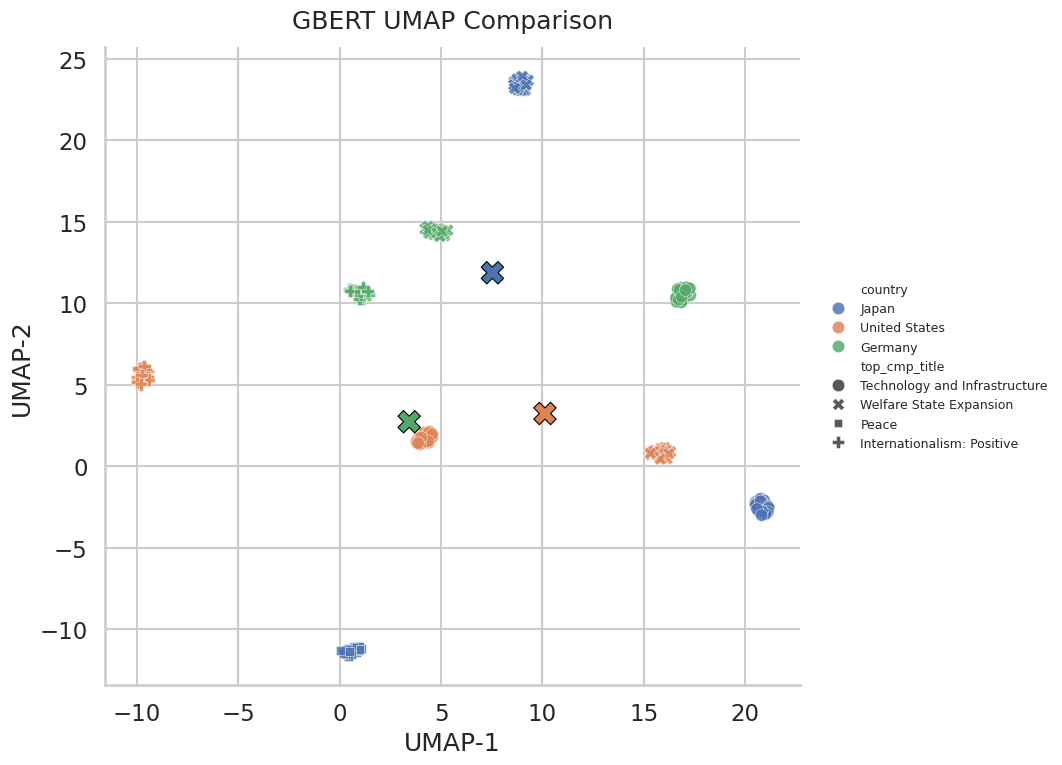

In [14]:
# 15. UMAP plot
fig, ax, umap_frame = model.plot_umap(
    texts=texts,
    country=countries,
    year=years,
    color_by="country",
    annotate=False,
)


/usr/local/lib/python3.12/dist-packages/gbert/service.py:2197: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x=value_col, y="cmp_title", palette="crest", ax=ax)


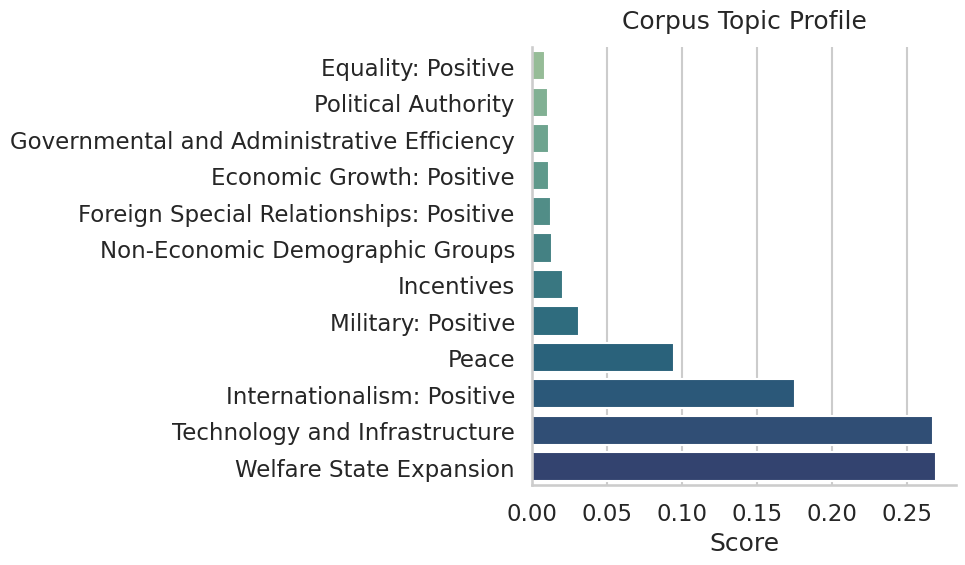

In [15]:
# 16. Topic profile bar plot
fig, ax = model.plot_topic_profile(
    profile,
    top_n=12,
    title="Corpus Topic Profile",
)


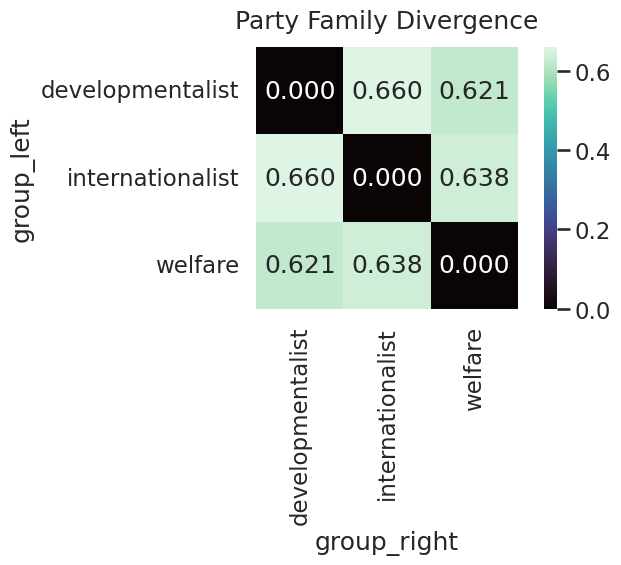

In [16]:
# 17. Group divergence heatmap
fig, ax, divergence_matrix = model.plot_group_divergence(
    comparison["pairwise_divergence"],
    title="Party Family Divergence",
)

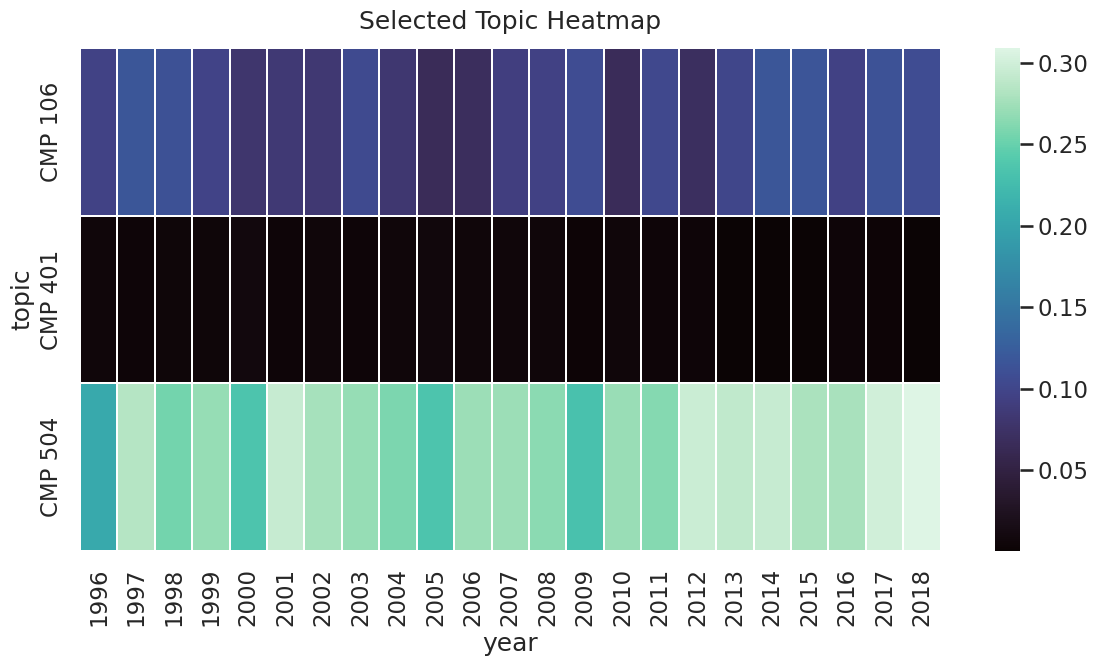

In [17]:
# 18. Topic heatmap from panel
fig, ax, heatmap = model.plot_topic_heatmap(
    panel,
    topics=[401, 504, 106],
    title="Selected Topic Heatmap",
)

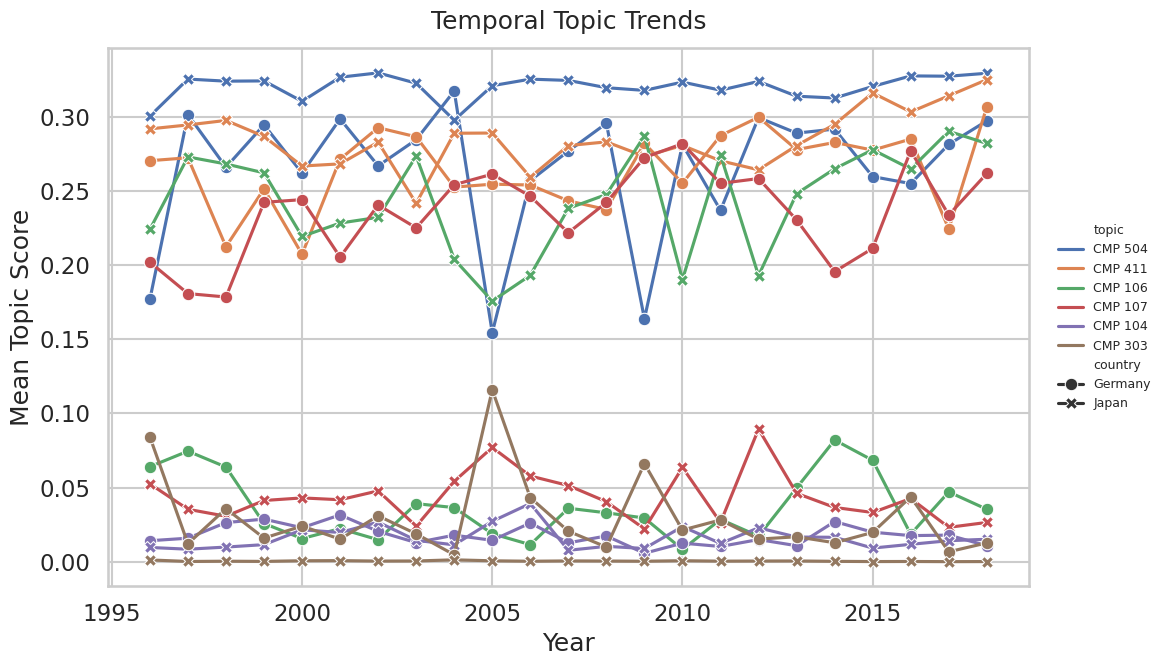

In [18]:
# 19. Temporal trend plot from panel
fig, ax, trend_df = model.plot_temporal_trends(
    panel,
    #topics=[401, 504, 106],
    countries=["Japan", "Germany", "France", "United Kingdom"],
    title="Temporal Topic Trends",
)

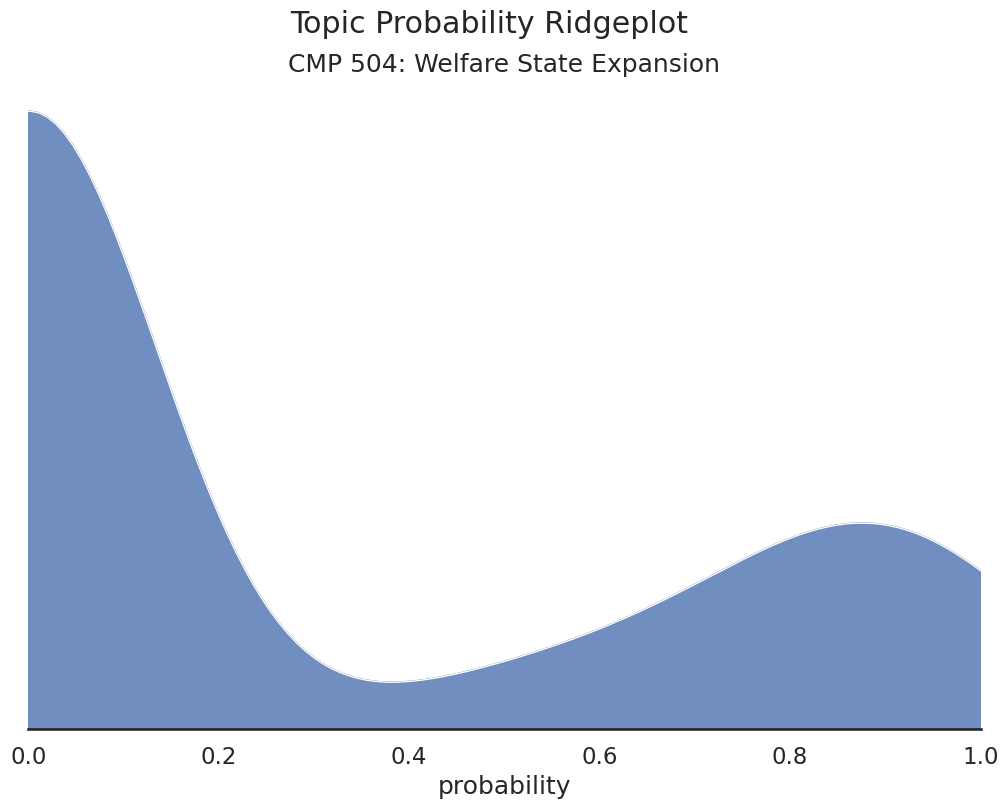

In [19]:
# 20. Ridgeplot from text-level analysis
g = model.plot_topic_ridgeplot(
    analysis,
    topics=[504],
    title="Topic Probability Ridgeplot",
)

# Adv

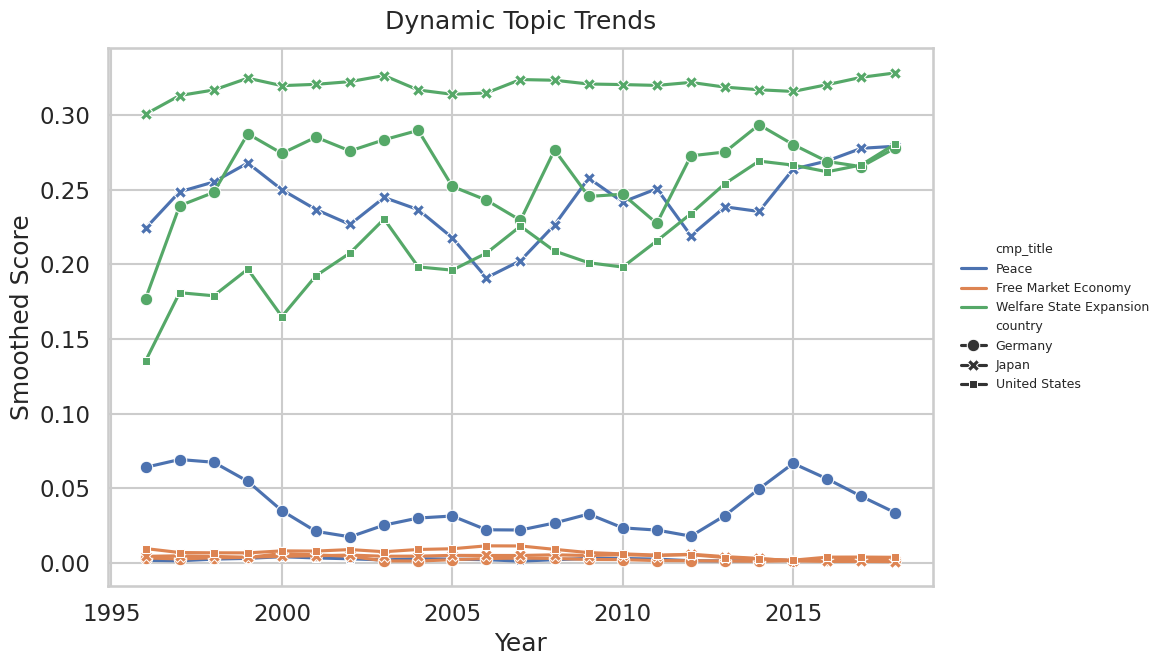

In [20]:
# Use this method when you want smoothed country-level topic trajectories rather than raw year-to-year values
dynamic_trends = model.estimate_dynamic_topic_trends(
    panel,
    topics=[401, 504, 106],
    countries=["Japan", "United States", "Germany"],
    smoothing_window=3,
)
#print(dynamic_trends.head())

fig, ax, trend_plot_data = model.plot_dynamic_topic_trends(dynamic_trends)

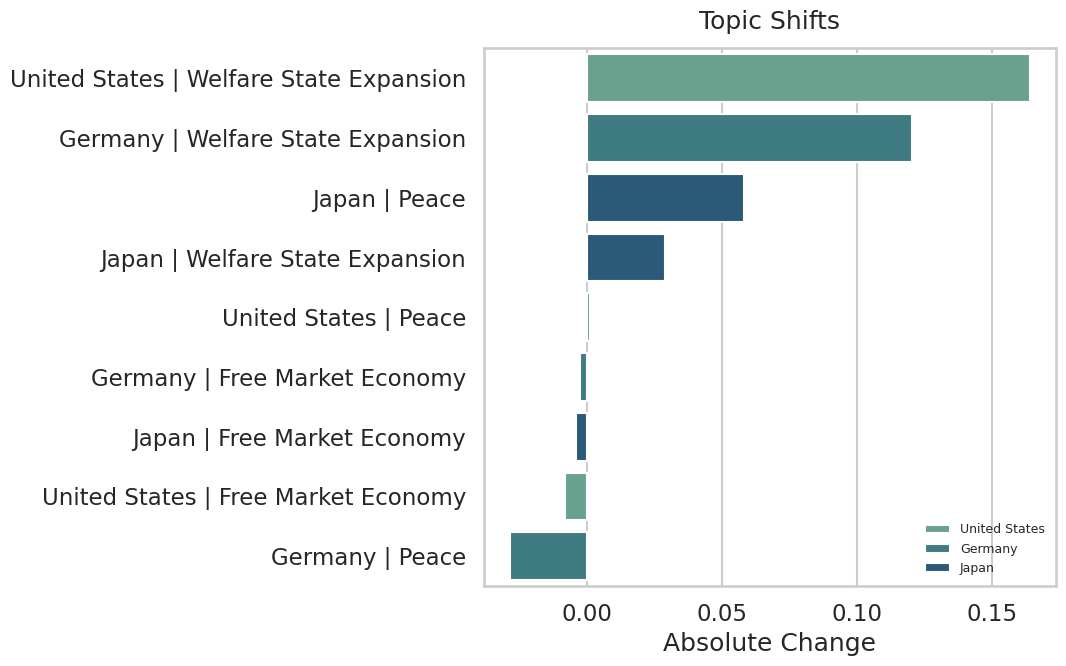

In [21]:
# Use this method to compare start-to-end change within each country or another panel grouping variable.
# It summarizes how much each topic moved between the first and last available year in the filtered panel.
topic_shifts = model.compare_topic_shifts(
    panel,
    topics=[401, 504, 106],
    group_col="country",
    start_year=1996,
    end_year=2018,
)
#print(topic_shifts.head())

fig, ax, topic_shift_plot = model.plot_topic_shifts(topic_shifts)

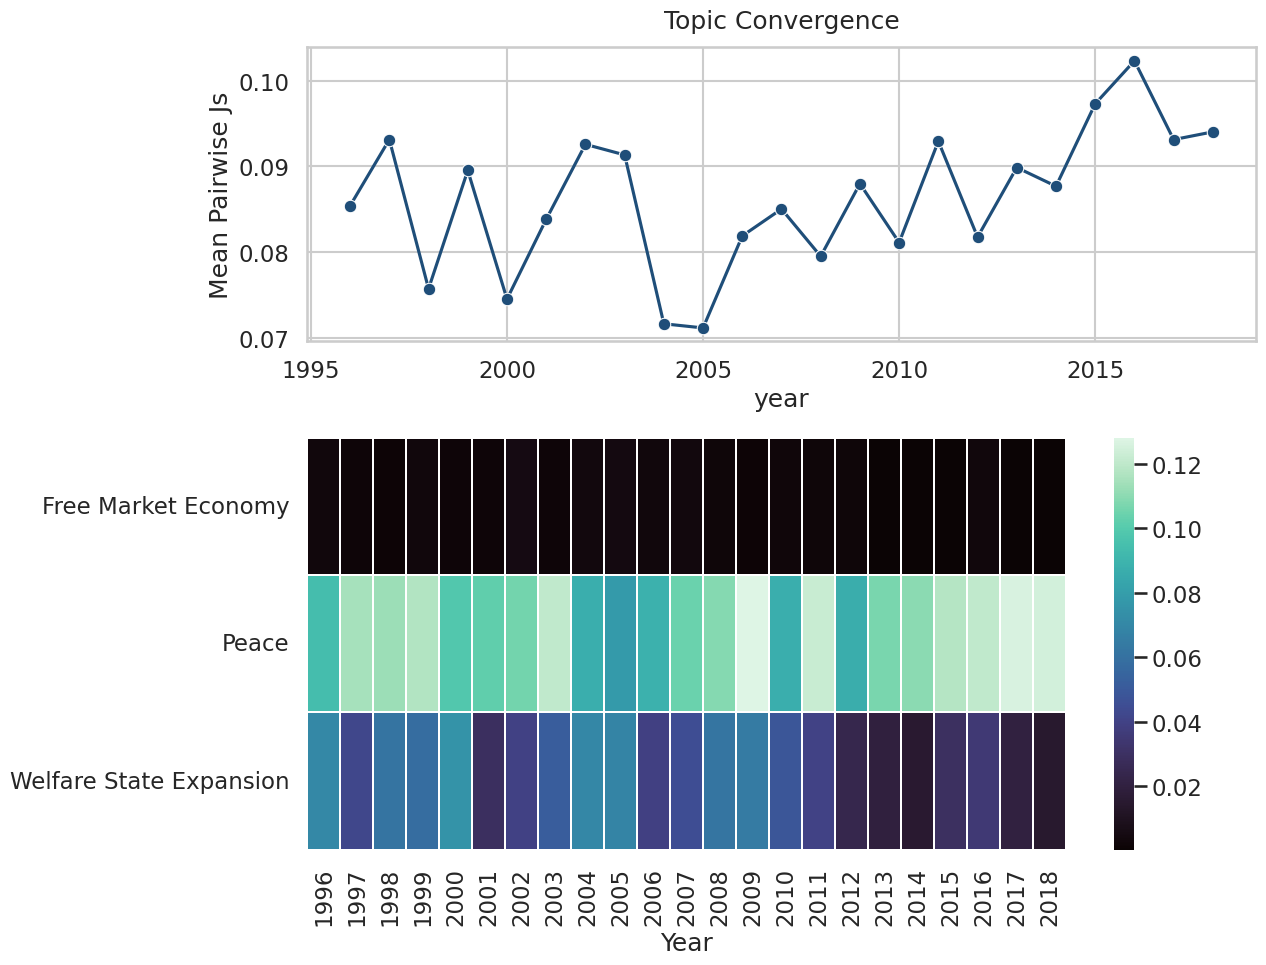

In [22]:
# Use this method to study whether countries are becoming more similar or more different over time.
# It combines topic-wise cross-country dispersion with pairwise Jensen-Shannon divergence.
convergence = model.compute_topic_convergence(
    panel,
    topics=[401, 504, 106],
)
#print(convergence["yearly_summary"].head())
#print(convergence["pairwise_divergence"].head())

fig, axes, convergence_plot = model.plot_topic_convergence(convergence)

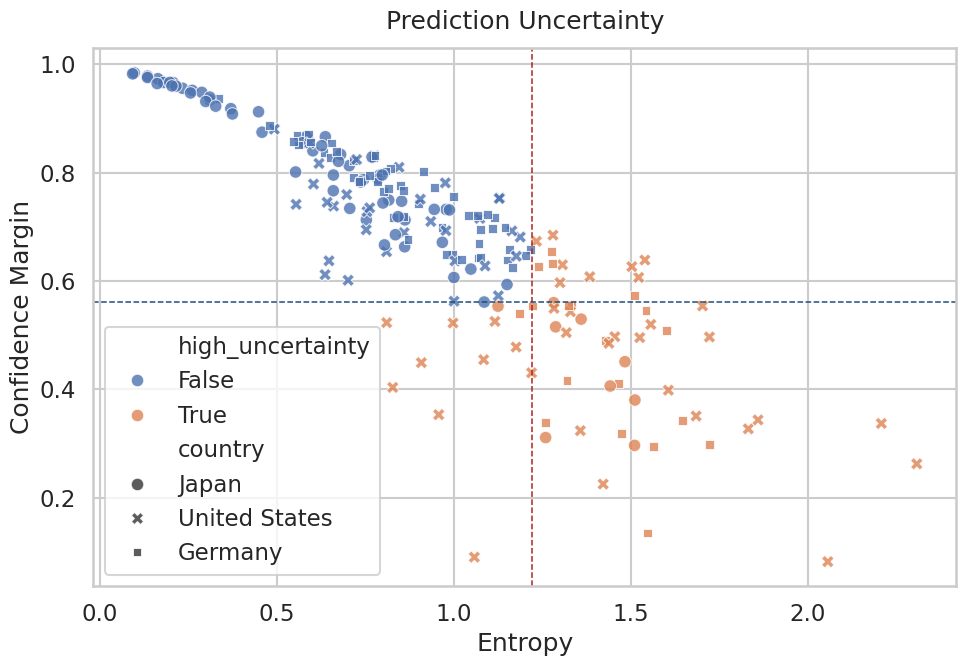

In [23]:
# Use this method to identify uncertain predictions at the text level.
# It relies on predictive entropy and top-class confidence margin and marks texts as high-uncertainty when either criterion is exceeded.
uncertainty = model.summarize_prediction_uncertainty(
    texts=texts,
    country=countries,
    year=years,
    group=party_family,
    entropy_quantile=0.75,
    margin_quantile=0.25,
)
#print(uncertainty["summary"])
#print(uncertainty["group_summary"].head())

fig, ax, uncertainty_plot = model.plot_prediction_uncertainty(uncertainty)

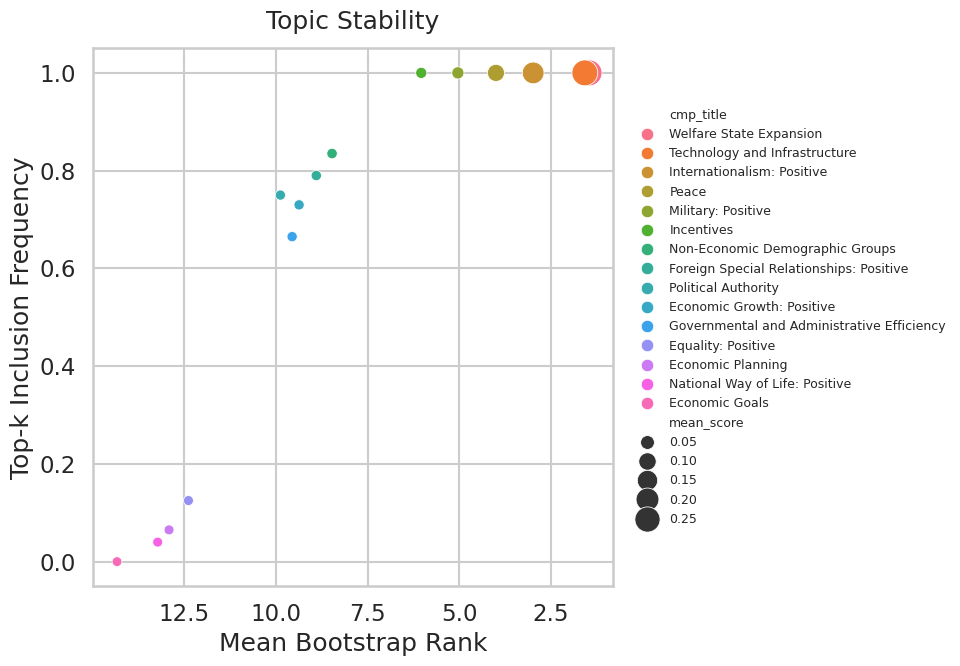

In [24]:
# Use this method to evaluate how stable topic rankings are under bootstrap resampling.
# This is helpful when you want to know whether the leading topics in a corpus are robust or highly sample-dependent.
stability = model.assess_topic_stability(
    texts=texts,
    country=countries,
    year=years,
    n_bootstrap=200,
    top_k=10,
)
#print(stability.head())

fig, ax, stability_plot = model.plot_topic_stability(stability)

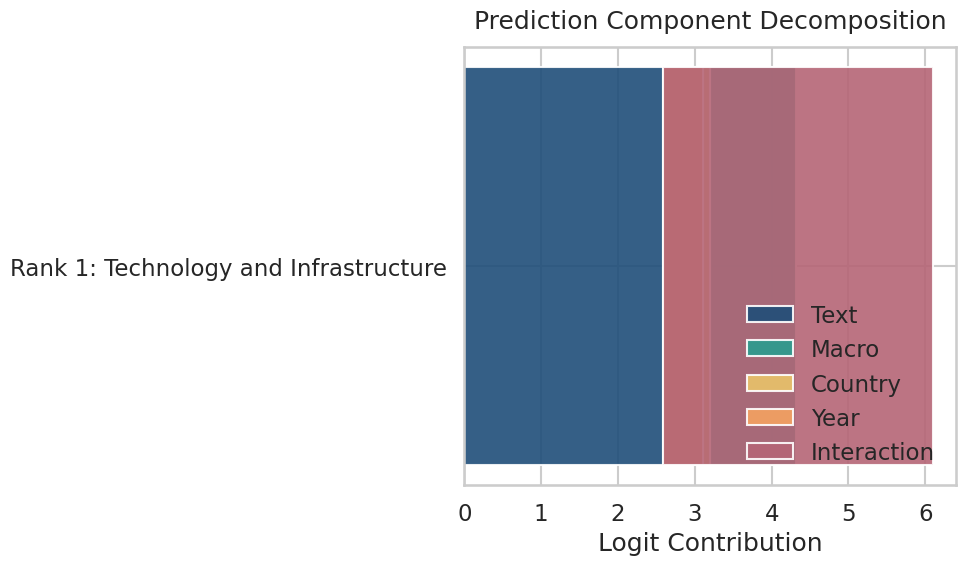

In [25]:
# Use this method to inspect how the model’s total logit for each predicted CMP topic is assembled from different sources: 
# text, macro conditions, country embedding, year embedding, and interaction terms.
components = model.decompose_prediction_components(
    texts=texts[:5],
    country=countries[:5],
    year=years[:5],
    top_k=3,
)
#print(components.head())

fig, ax, component_plot = model.plot_prediction_components(components, text_index=0, rank=1)

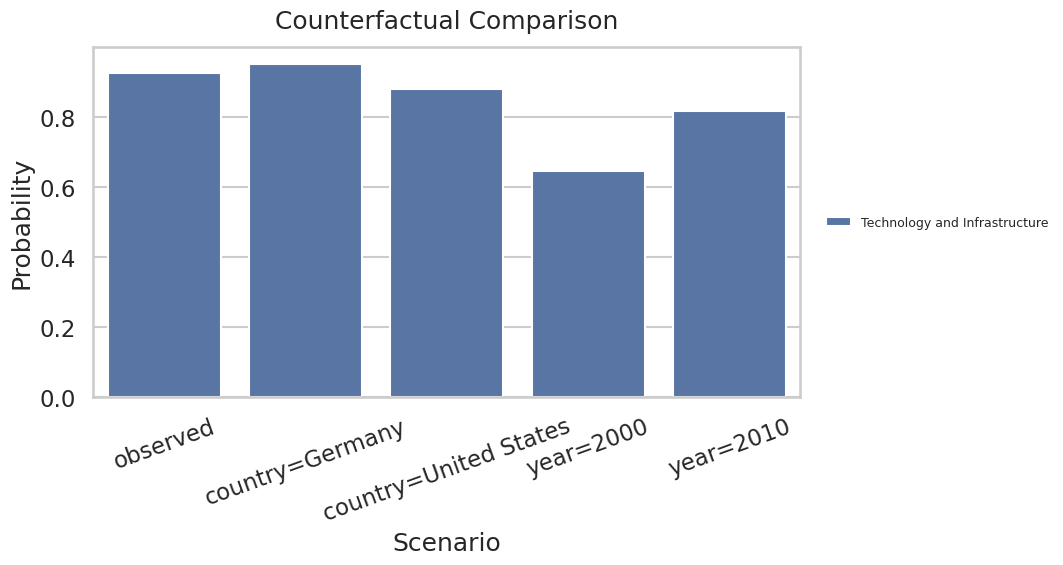

In [26]:
# Use this method to hold the text constant while changing political context. 
# This is useful when you want to ask how the same sentence would be classified under another country or another year.
counterfactuals = model.simulate_counterfactuals(
    text="The government should expand industrial investment and modern infrastructure.",
    country="Japan",
    year=2018,
    counterfactual_countries=["Germany", "United States"],
    counterfactual_years=[2000, 2010],
    top_k=3,
)
#print(counterfactuals.head(12))

fig, ax, counterfactual_plot = model.plot_counterfactuals(counterfactuals, rank=1)

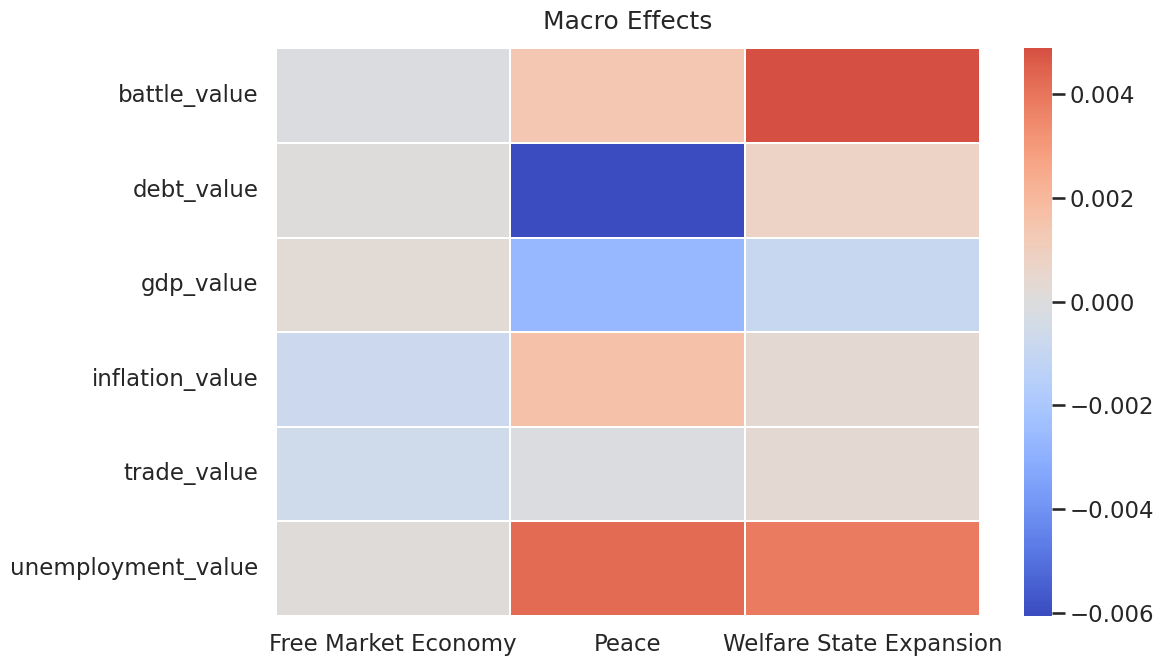

In [27]:
# Use this method to estimate topic sensitivity to perturbations in the macro variables used by the model. 
# The method shifts each macro feature up and down in standardized space and reports how topic probabilities respond on average.
macro_effects = model.estimate_macro_effects(
    texts=texts,
    country=countries,
    year=years,
    topic_codes=[401, 504, 106],
    step_size=0.5,
)
#print(macro_effects.head())

fig, ax, macro_effect_plot = model.plot_macro_effects(macro_effects)